In [1]:
import numpy as np
import pickle
from nilearn import datasets

abide = datasets.fetch_abide_pcp(
    n_subjects=None,
    derivatives=['rois_cc200', 'rois_ho'],
)

pheno  = abide['phenotypic']
sig_cc = abide['rois_cc200']
sig_ho = abide['rois_ho']

y    = (pheno['DX_GROUP'] == 1).astype(int).values
age  = pheno['AGE_AT_SCAN'].values
sex  = pheno['SEX'].values
site = pheno['SITE_ID'].astype(str).values

print("subjects:", len(sig_cc), len(sig_ho))
print("class counts [control, autism]:", np.bincount(y))
print("regions cc200:", {s.shape[1] for s in sig_cc})
print("regions ho:   ", {s.shape[1] for s in sig_ho})
T_all = [s.shape[0] for s in sig_cc]
print("T range:", min(T_all), max(T_all))
print("missing age:", np.isnan(age).sum())
print(pheno['SITE_ID'].value_counts())

with open('abide_cache.pkl', 'wb') as f:
    pickle.dump(dict(sig_cc=sig_cc, sig_ho=sig_ho, y=y,
                     age=age, sex=sex, site=site), f)

[fetch_abide_pcp] Dataset directory found: C:\Users\Jayanth\nilearn_data\ABIDE_pcp
subjects: 871 871
class counts [control, autism]: [468 403]
regions cc200: {200}
regions ho:    {111}
T range: 78 316
missing age: 0
SITE_ID
NYU         172
UM_1         86
USM          67
UCLA_1       64
PITT         50
MAX_MUN      46
TRINITY      44
YALE         41
UM_2         34
KKI          33
OLIN         28
LEUVEN_1     28
LEUVEN_2     28
SDSU         27
SBL          26
OHSU         25
STANFORD     25
UCLA_2       21
CALTECH      15
CMU          11
Name: count, dtype: int64


In [3]:
import numpy as np, pandas as pd, pickle

d = pickle.load(open('abide_cache.pkl', 'rb'))
y, age, sex, site = d['y'], d['age'], d['sex'], d['site']

def zscore(x):
    sd = x.std(axis=0); sd[sd == 0] = 1
    return (x - x.mean(axis=0)) / sd

def range_feats(signals):                      # feature set A
    return np.array([zscore(s).max(0) - zscore(s).min(0) for s in signals])

def corr_feats(signals):                       # feature set B
    N = signals[0].shape[1]
    iu = np.triu_indices(N, k=1)
    out = []
    for s in signals:
        c = np.nan_to_num(np.corrcoef(s.T))
        out.append(np.arctanh(np.clip(c[iu], -0.999, 0.999)))
    return np.array(out)

feats = {
    'cc200_range': range_feats(d['sig_cc']),
    'cc200_corr':  corr_feats(d['sig_cc']),
    'ho_range':    range_feats(d['sig_ho']),
    'ho_corr':     corr_feats(d['sig_ho']),
}
for k, v in feats.items():
    print(k, v.shape, np.isnan(v).sum())

demo = pd.DataFrame({'age': age, 'sex': (sex == 1).astype(int)})
demo = pd.concat([demo, pd.get_dummies(site, prefix='site').astype(int)], axis=1)
print(demo.shape, pd.Series(sex).value_counts().to_dict())

np.savez('features.npz', y=y, demo=demo.values, demo_cols=demo.columns.values, **feats)

c:\Users\Jayanth\Downloads\DSA\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\Jayanth\Downloads\DSA\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


cc200_range (871, 200) 0
cc200_corr (871, 19900) 0
ho_range (871, 111) 0
ho_corr (871, 6105) 0
(871, 22) {1: 727, 2: 144}


In [2]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

d = np.load('features.npz', allow_pickle=True)
y, demo = d['y'], d['demo'].astype(float)

# dev set (15%) for choosing C; the other 85% is used for 10-fold CV
cv_idx, dev_idx = train_test_split(np.arange(len(y)), test_size=0.15,
                                   stratify=y, random_state=0)

def build(brain, setting):
    if setting == 'brain only':       return brain
    if setting == '+demo':            return np.hstack([brain, demo])
    if setting == '+demo (no age)':   return np.hstack([brain, demo[:, 1:]])
    if setting == 'demo only':        return demo

def lr(C):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))

Cs = [1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1]
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)
rows = []

def run(name, setting, X):
    dev_acc = {C: lr(C).fit(X[cv_idx], y[cv_idx]).score(X[dev_idx], y[dev_idx]) for C in Cs}
    bestC = max(dev_acc, key=dev_acc.get)
    s = cross_val_score(lr(bestC), X[cv_idx], y[cv_idx], cv=cv)
    rows.append((name, setting, bestC, s.mean(), s.std()))

for fname in ['cc200_range', 'cc200_corr', 'ho_range', 'ho_corr']:
    for setting in ['brain only', '+demo', '+demo (no age)']:
        run(fname, setting, build(d[fname], setting))
run('none', 'demo only', demo)

print(pd.DataFrame(rows, columns=['features', 'setting', 'C', 'cv_acc', 'std']))
print('majority baseline:', 1 - y.mean() if y.mean() < 0.5 else y.mean())

       features         setting       C    cv_acc       std
0   cc200_range      brain only  0.0010  0.540541  0.032545
1   cc200_range           +demo  0.0100  0.504054  0.080187
2   cc200_range  +demo (no age)  0.0100  0.510811  0.081485
3    cc200_corr      brain only  0.0001  0.666216  0.058296
4    cc200_corr           +demo  0.0001  0.664865  0.056949
5    cc200_corr  +demo (no age)  0.0001  0.666216  0.057666
6      ho_range      brain only  0.0100  0.485135  0.061170
7      ho_range           +demo  0.0100  0.486486  0.059213
8      ho_range  +demo (no age)  0.0100  0.493243  0.056126
9       ho_corr      brain only  0.0001  0.650000  0.063800
10      ho_corr           +demo  0.0001  0.650000  0.063800
11      ho_corr  +demo (no age)  0.0001  0.650000  0.063800
12         none       demo only  0.0100  0.529730  0.066147
majority baseline: 0.5373134328358209


In [ ]:
from sklearn.svm import SVC

kernels = {'linear': dict(kernel='linear'),
           'poly2':  dict(kernel='poly', degree=2),
           'sigmoid':dict(kernel='sigmoid'),
           'rbf':    dict(kernel='rbf')}
Cs_svm = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10]

def svm(kw, C):
    return make_pipeline(StandardScaler(), SVC(C=C, **kw))

svm_rows = []
def run_svm(fname, kname, setting, X):
    kw = kernels[kname]
    dev = {C: svm(kw, C).fit(X[cv_idx], y[cv_idx]).score(X[dev_idx], y[dev_idx]) for C in Cs_svm}
    bestC = max(dev, key=dev.get)
    s = cross_val_score(svm(kw, bestC), X[cv_idx], y[cv_idx], cv=cv)
    svm_rows.append((fname, kname, setting, bestC, s.mean(), s.std()))
    print(svm_rows[-1])

for fname in ['cc200_corr', 'ho_corr', 'cc200_range', 'ho_range']:
    for kname in kernels:
        for setting in ['brain only', '+demo', '+demo (no age)']:
            run_svm(fname, kname, setting, build(d[fname], setting))
for kname in kernels:
    run_svm('none', kname, 'demo only', demo)

print(pd.DataFrame(svm_rows, columns=['features','kernel','setting','C','cv_acc','std']))

#(This was taking a long time running ) 

('cc200_corr', 'linear', 'brain only', 0.0001, np.float64(0.6891891891891893), np.float64(0.06133408496167685))


KeyboardInterrupt: 

In [10]:
from sklearn.svm import SVC
from sklearn.metrics.pairwise import (linear_kernel, polynomial_kernel,
                                      rbf_kernel, sigmoid_kernel)
from sklearn.metrics import f1_score

Cs_svm = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100]

def gram(X, kname):
    g = 1.0 / (X.shape[1] * X[cv_idx].var())      # like sklearn's 'scale'
    if kname == 'linear':  return linear_kernel(X)
    if kname == 'poly2':   return polynomial_kernel(X, degree=2, gamma=g, coef0=0)
    if kname == 'rbf':     return rbf_kernel(X, gamma=g)
    if kname == 'sigmoid': return sigmoid_kernel(X, gamma=g, coef0=0)

def eval_kernel(K):
    ycv = y[cv_idx]
    Kcv  = K[np.ix_(cv_idx, cv_idx)]
    Kdev = K[np.ix_(dev_idx, cv_idx)]
    dev = {C: SVC(kernel='precomputed', C=C).fit(Kcv, ycv).score(Kdev, y[dev_idx])
           for C in Cs_svm}
    bestC = max(dev, key=dev.get)
    accs = []
    f1scores=[]
    for tr, te in cv.split(Kcv, ycv):
      m = SVC(kernel='precomputed', C=bestC)
      m.fit(Kcv[np.ix_(tr, tr)], ycv[tr])

      K_test = Kcv[np.ix_(te, tr)]
      y_pred = m.predict(K_test)

      accs.append(m.score(K_test, ycv[te]))
      f1scores.append(f1_score(ycv[te], y_pred, pos_label=1))

    return bestC, np.mean(accs), np.std(accs), np.mean(f1scores)

rows = []
for fname in ['cc200_corr', 'ho_corr','cc200_range', 'ho_range']:
    for kname in ['linear', 'poly2', 'rbf', 'sigmoid']:
        K = gram(d[fname], kname)
        rows.append((fname, kname, *eval_kernel(K)))
        print(rows[-1])

print(pd.DataFrame(rows, columns=['features', 'kernel', 'C', 'cv_acc', 'std','flscore']))

('cc200_corr', 'linear', 0.001, np.float64(0.6594594594594596), np.float64(0.05945945945945945), np.float64(0.6015688325431304))
('cc200_corr', 'poly2', 10, np.float64(0.7027027027027026), np.float64(0.0650897004259043), np.float64(0.6615727167327681))
('cc200_corr', 'rbf', 10, np.float64(0.6770270270270271), np.float64(0.05586493677998482), np.float64(0.6343442899056047))
('cc200_corr', 'sigmoid', 1e-05, np.float64(0.5378378378378379), np.float64(0.005405405405405439), np.float64(0.0))
('ho_corr', 'linear', 0.01, np.float64(0.6797297297297297), np.float64(0.05860877957351741), np.float64(0.6327462616179869))
('ho_corr', 'poly2', 10, np.float64(0.6581081081081082), np.float64(0.05798226473763497), np.float64(0.6329585365151529))
('ho_corr', 'rbf', 1, np.float64(0.6418918918918919), np.float64(0.05677284199351355), np.float64(0.5474417084205372))
('ho_corr', 'sigmoid', 1e-05, np.float64(0.5378378378378379), np.float64(0.005405405405405439), np.float64(0.0))
('cc200_range', 'linear', 0.0

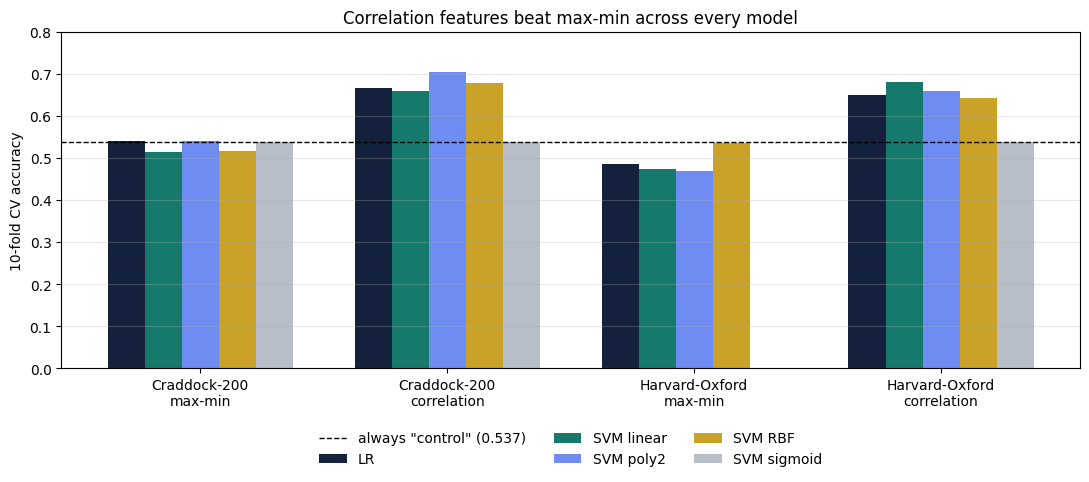

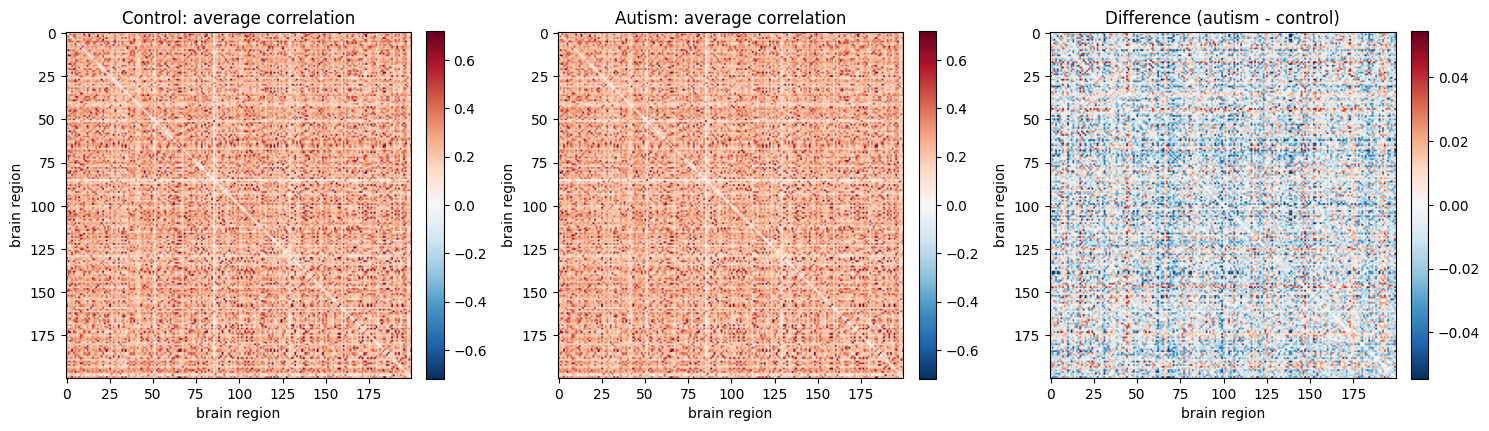

largest group difference: 0.092
typical correlation size: 0.262


In [4]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- Chart 1: every model, side by side ----------
models = ['LR', 'SVM linear', 'SVM poly2', 'SVM RBF', 'SVM sigmoid']
acc = {
    'Craddock-200\nmax-min':        [0.541, 0.515, 0.541, 0.516, 0.538],
    'Craddock-200\ncorrelation':    [0.666, 0.659, 0.703, 0.677, 0.538],
    'Harvard-Oxford\nmax-min':      [0.485, 0.473, 0.469, 0.535, np.nan],  # sigmoid not recorded
    'Harvard-Oxford\ncorrelation':  [0.650, 0.680, 0.658, 0.642, 0.538],
}
colors = ['#14213D', '#157A6B', '#6F8CF2', '#C9A227', '#B7BEC7']

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(acc))
width = 0.15
for i, m in enumerate(models):
    vals = [v[i] for v in acc.values()]
    ax.bar(x + (i - (len(models) - 1) / 2) * width, vals, width, label=m, color=colors[i])

ax.axhline(0.537, ls='--', color='black', lw=1, label='always "control" (0.537)')
ax.set_xticks(x)
ax.set_xticklabels(list(acc.keys()))
ax.set_ylim(0, 0.8)
ax.set_ylabel('10-fold CV accuracy')
ax.set_title('Correlation features beat max-min across every model')
ax.grid(axis='y', alpha=0.3)
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15), frameon=False)
plt.tight_layout()
fig.savefig('results_all_models.png', dpi=200, bbox_inches='tight')
plt.show()

# ---------- Chart 2: average correlation, control vs autism ----------
d = np.load('features.npz', allow_pickle=True)
y = d['y']                       # 1 = autism, 0 = control
F = d['cc200_corr']              # (871, 19900): Fisher-z correlations, upper triangle only
N = 200
iu = np.triu_indices(N, k=1)

def to_matrix(vec):
    M = np.zeros((N, N))
    M[iu] = vec                  # fill the upper triangle
    return M + M.T               # mirror it to get the full symmetric matrix

ctl = to_matrix(F[y == 0].mean(axis=0))
asd = to_matrix(F[y == 1].mean(axis=0))
diff = asd - ctl

v1 = np.percentile(np.abs(np.concatenate([ctl[iu], asd[iu]])), 99)
v2 = np.percentile(np.abs(diff[iu]), 99)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
panels = [(ctl, 'Control: average correlation', v1),
          (asd, 'Autism: average correlation', v1),
          (diff, 'Difference (autism - control)', v2)]
for ax, (M, title, v) in zip(axes, panels):
    im = ax.imshow(M, cmap='RdBu_r', vmin=-v, vmax=v)
    ax.set_title(title)
    ax.set_xlabel('brain region')
    ax.set_ylabel('brain region')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
fig.savefig('corr_heatmaps.png', dpi=200, bbox_inches='tight')
plt.show()

print('largest group difference:', round(np.abs(diff).max(), 3))
print('typical correlation size:', round(np.abs(ctl[iu]).mean(), 3))